In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos50.56_Xpos41.53500000000000400000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos50.4_Xpos41.59500000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos50.48_Xpos41.4600000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos44.464_Xpos41.400000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos48.688_Xpos41.5300000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.16_Xpos41.6400000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos42.352000000000004_Xpos42.1800000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos42.352000000000004_Xpos41.7900000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.16_Xpos41.5800000.root
proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos50.64_Xpos41.50500000.root
proc_F_AC_LGAD_40um_strip_NEv

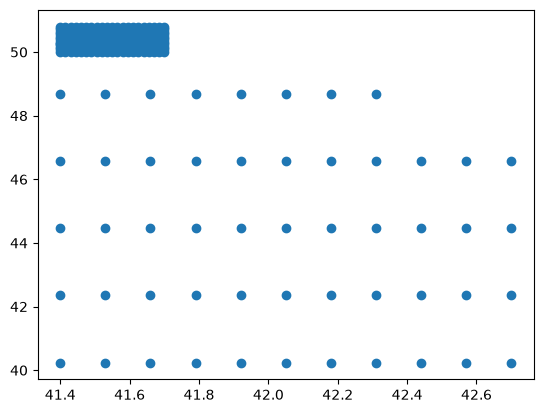

In [3]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = np.linspace(50.0, 50.8, 11)
X_range = np.linspace(41.4, 41.7, 21)

map_plot_x = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.trc")[0]), 3)
    z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])        , 3)
    map_plot_x.append(x_pos)
    map_plot_z.append(z_pos)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

# Read and store specific branches.

In [4]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_50.56_41.535', 'pos_50.4_41.595', 'pos_50.48_41.46', 'pos_44.464_41.4', 'pos_48.688_41.53', 'pos_50.16_41.64', 'pos_42.352_42.18', 'pos_42.352_41.79', 'pos_50.16_41.58', 'pos_50.64_41.505', 'pos_50.32_41.415', 'pos_42.352_41.92', 'pos_50.72_41.535', 'pos_42.352_41.53', 'pos_50.32_41.64', 'pos_50.32_41.595', 'pos_50.32_41.655', 'pos_40.24_42.7', 'pos_50.32_41.58', 'pos_50.08_41.565', 'pos_50.0_41.685', 'pos_50.8_41.565', 'pos_46.576_41.79', 'pos_50.64_41.655', 'pos_50.72_41.64', 'pos_50.0_41.61', 'pos_50.8_41.58', 'pos_50.08_41.64', 'pos_44.464_41.66', 'pos_50.0_41.565', 'pos_40.24_42.31', 'pos_50.72_41.55', 'pos_50.16_41.685', 'pos_50.4_41.43', 'pos_50.48_41.7', 'pos_50.24_41.46', 'pos_50.48_41.61', 'pos_50.72_41.625', 'pos_50.08_41.505', 'pos_50.0_41.55', 'pos_50.64_41.52', 'pos_50.64_41.445', 'pos_50.56_41.7', 'pos_50.8_41.61', 'pos_50.16_41.445', 'pos_50.32_41.43', 'pos_50.48_41.67', 'pos_50.4_41.685', 'pos_50.0_41.625', 'pos_50.08_41.685', 'pos_42.352_42.05', 'pos_5

## Amplitude and NEvents vs z position.

20
41.55 [41.84292477 28.05587202 41.60147409  7.56327162]
[np.float64(7.4857891031690365), np.float64(8.208669354273612), np.float64(8.983104233244012), np.float64(9.809293531870638), np.float64(10.686756360562438), np.float64(11.6142521364303), np.float64(12.58971715160644), np.float64(13.610222706068674), np.float64(14.671960407788397), np.float64(15.77025927060211), np.float64(16.899637661214577), np.float64(18.053891028400834), np.float64(19.226213847480455), np.float64(20.409351570817034), np.float64(21.59577588391729), np.float64(22.777874531659325), np.float64(23.948145665708175), np.float64(25.099386250437643), np.float64(26.224864607796594), np.float64(27.318468606637133), np.float64(28.374823116561053)]
19
41.55 [43.60676926 28.02452355 41.61215736  7.24790113]
[np.float64(7.712752152502257), np.float64(8.42736247483895), np.float64(9.191229318102078), np.float64(10.00464352235248), np.float64(10.867313089785137), np.float64(11.77829427524837), np.float64(12.735934054454615)

/tmp/ipykernel_571775/535061706.py:42: OptimizeWarning: Covariance of the parameters could not be estimated
  params = curve_fit(sigmoid, X_range[mask], mean_amps[mask], p0 = (np.min(mean_amps[mask]), np.max(mean_amps[mask]), np.mean(X_range), 10))


20
41.55 [43.23622571 28.19564807 41.60866795  7.32016144]
[np.float64(7.71171015985462), np.float64(8.432164085957783), np.float64(9.202489563144512), np.float64(10.022922318705469), np.float64(10.893088289213972), np.float64(11.811933000686151), np.float64(12.777663524161271), np.float64(13.787707942201889), np.float64(14.838697030701349), np.float64(15.926472180842898), np.float64(17.046122435570393), np.float64(18.19205192859856), np.float64(19.358077092146726), np.float64(20.537550904933834), np.float64(21.72350939400404), np.float64(22.908833812154665), np.float64(24.086420601844363), np.float64(25.24935059114442), np.float64(26.391048933321102), np.float64(27.505428090428182), np.float64(28.587007571489607)]
20
41.55 [42.05253891 28.09386658 41.59894917  7.31510709]
[np.float64(7.9555807053920775), np.float64(8.687606755077983), np.float64(9.468285461119843), np.float64(10.297465555155762), np.float64(11.17435825741912), np.float64(12.097476273950269), np.float64(13.064588110514

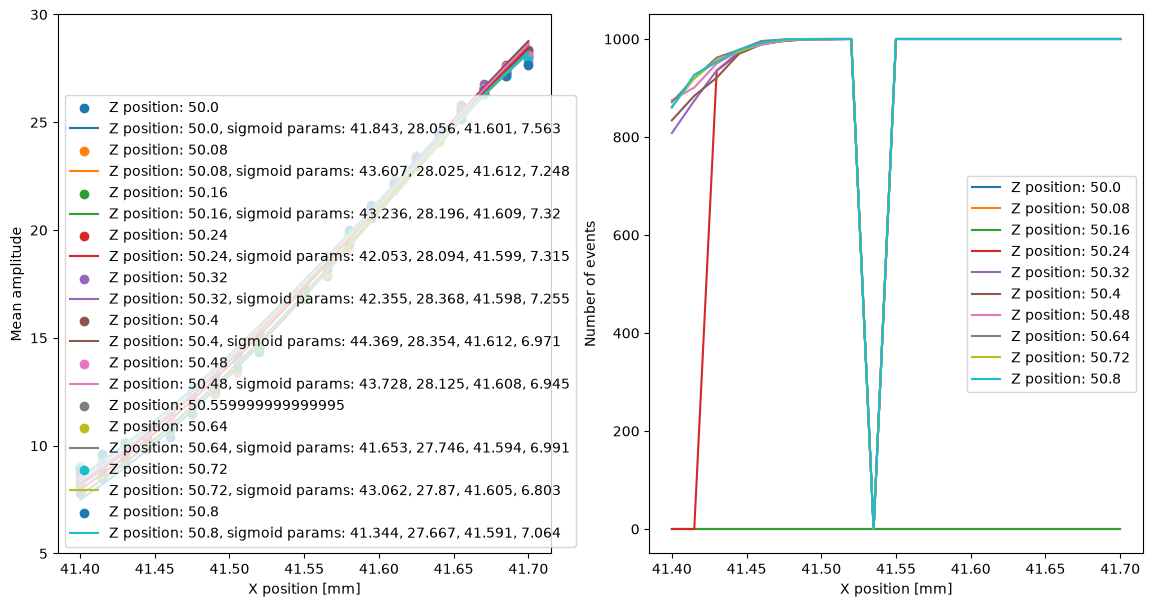

In [ ]:
cols = 2
rows = 1
size = 7

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
# Z_range = [50.0, 50.8]
for z_i, z in enumerate(Z_range):
    mean_amps = []
    n_events = []
    for x_i, x in enumerate(X_range):
        # l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
        l = f"pos_{z}_{x}"
        try:
            # print(z, x)
            mean_amps.append(np.mean(amp[l][:,0]))
            n_events.append(np.sum(timestamps[l][:,0]>0))
            # print(l, mean_amps[-1]) # , n_events[-1])
        except:
            # print(f"{l} is not ready or taken yet")
            mean_amps.append(0)
            n_events.append(0)
    
    sorting = np.argsort(X_range)
    mean_amps = np.array(mean_amps)
    n_events = np.array(n_events)

    # print(X_range[mean_amps != 0])
    # print(mean_amps[mean_amps != 0])

    ax[0].scatter(X_range, mean_amps, label = f"Z position: {z}")
    ax[0].set_xlabel("X position [mm]")
    ax[0].set_ylabel("Mean amplitude")
    ax[0].set_ylim(5, 30)

    # try:
    mask = (mean_amps != 0) #  & (mean_amps > 41.4) & (mean_amps < 41.7)
    print(np.sum(mask))
    if (np.sum(mask) == 0): continue
    params = curve_fit(sigmoid, X_range[mask], mean_amps[mask], p0 = (np.min(mean_amps[mask]), np.max(mean_amps[mask]), np.mean(X_range), 10))
    print(np.mean(X_range), params[0])
    sigmoid_y = [sigmoid(i, params[0][0], params[0][1], params[0][2], params[0][3]) for i in X_range]
    print(sigmoid_y)
    ax[0].plot(X_range, sigmoid_y, label = f"Z position: {z}, sigmoid params: {np.round(params[0][0], 3)}, {np.round(params[0][1], 3)}, {np.round(params[0][2], 3)}, {np.round(params[0][3], 3)}")
    ax[0].legend()
    ax[1].plot(X_range, n_events, label = f"Z position: {z}")
    ax[1].set_xlabel("X position [mm]")
    ax[1].set_ylabel("Number of events")

    plt.legend()
plt.show()

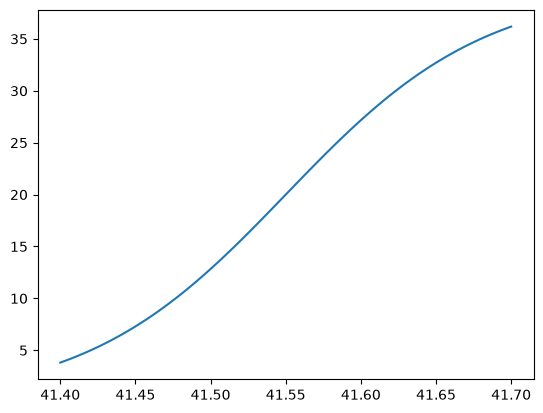

In [17]:
x_arr = np.linspace(41.4, 41.7, 100)
y_arr = sigmoid(x_arr, 40, 7, 41.55, 15)

plt.plot(x_arr, y_arr)
plt.show()

pos_50.56_41.535 16.119956356048583

pos_50.56_41.7 28.3549207611084

pos_50.56_41.67 26.542291667938233

pos_50.56_41.55 17.361787514686583

pos_50.56_41.505 14.152910264015198

pos_50.56_41.655 25.754077402114866

pos_50.56_41.475 12.203213351249694

pos_50.56_41.64 24.57195005607605

pos_50.56_41.49 13.248001385688783

pos_50.56_41.46 11.443158284187318

pos_50.56_41.58 19.881051851272584

pos_50.56_41.445 10.571019152641297

pos_50.56_41.685 27.539376197814942

pos_50.56_41.4 8.764578583478928

pos_50.56_41.43 10.070786700248718

pos_50.56_41.565 18.657358130455016

pos_50.56_41.52 15.135100217819215

pos_50.56_41.595 21.298387842178343

pos_50.56_41.61 22.43689545726776

pos_50.56_41.625 23.405569227218628

[41.4   41.43  41.445 41.46  41.475 41.49  41.505 41.52  41.535 41.55
 41.565 41.58  41.595 41.61  41.625 41.64  41.655 41.67  41.685 41.7  ]
[ 8.76457858 10.0707867  10.57101915 11.44315828 12.20321335 13.24800139
 14.15291026 15.13510022 16.11995636 17.36178751 18.65735813 19

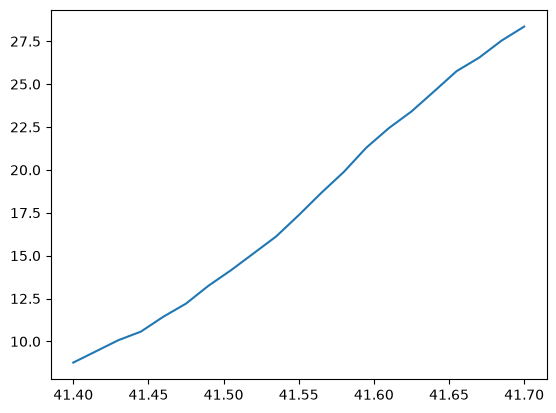

In [ ]:
x_range = []
n_events = []
amp_means = []

for i in timestamps.keys():
    z = float(i.split("_")[1])
    if (z == 50.56):
        x = float(i.split("pos_")[1].split("_")[1])
        x_range.append(x)
        amp_means.append(np.mean(amp[i][:,0]))
        
        print(i, np.mean(amp[i][:,0]))
        print()

sort_condition = np.argsort(x_range)

x_range = np.array(x_range)[sort_condition]
amp_means = np.array(amp_means)[sort_condition]

print(x_range)
print(amp_means)

plt.plot(x_range, amp_means)
plt.show()